# 04 QSVM en hardware real de IBM

El kernel del cuaderno `01`, pero medido en una QPU de verdad: calculamos la matriz de kernel con circuitos *compute-uncompute* en un backend de IBM, entrenamos el `SVC` clásico de siempre y comparamos contra la referencia exacta y contra Aer.

Referencias: cuaderno `01` de esta sesión (el porqué del mapa y del *target alignment*), cuaderno `01` de la sesión 01 (envío a IBM) y las diapositivas de coste de esta sesión.

> **Aviso de coste:** enviar a hardware puede consumir créditos o tiempo de tu plan. Por eso el cuaderno trae una versión *mini* del problema, una referencia local que siempre funciona y un interruptor `EJECUTAR_EN_HARDWARE = False` que solo debes poner a `True` cuando quieras enviar de verdad.


In [1]:
!pip install -q qiskit qiskit-aer qiskit-ibm-runtime scikit-learn matplotlib pylatexenc


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


## 1. Primero, el tamaño del problema

En las diapositivas contamos el QSVM completo: 67 ejemplos de entrenamiento dan 4.489 circuitos únicos entre la matriz de entrenamiento y el bloque train contra test. Para una primera vez en hardware recortamos a propósito: 16 ejemplos de entrenamiento y 8 de test, elegidos al azar pero equilibrados por clase.

Con la simetría del kernel ($k(x_i, x_j) = k(x_j, x_i)$) solo hay que enviar los pares únicos. La diagonal no se ahorra: en un simulador vale 1 por construcción, pero en hardware mide cuánto se parece un estado a sí mismo tras pasar por el dispositivo, y eso ya es información.


In [2]:
N_TRAIN, N_TEST, SHOTS = 16, 8, 1024

def circuitos_unicos(n_train, n_test):
    return n_train * (n_train + 1) // 2 + n_train * n_test

print(f"Mini (hoy):   {circuitos_unicos(N_TRAIN, N_TEST)} circuitos x {SHOTS} shots = {circuitos_unicos(N_TRAIN, N_TEST) * SHOTS:,} shots")
print(f"Completo:    {circuitos_unicos(67, 33)} circuitos x {SHOTS} shots = {circuitos_unicos(67, 33) * SHOTS:,} shots")
print(f"Si N=1000:   {circuitos_unicos(1000, 0):,} circuitos solo para la matriz de entrenamiento")


Mini (hoy):   264 circuitos x 1024 shots = 270,336 shots
Completo:    4489 circuitos x 1024 shots = 4,596,736 shots
Si N=1000:   500,500 circuitos solo para la matriz de entrenamiento


## 2. Datos: iris fácil, ahora con los 4 rasgos

Mismo problema fácil del cuaderno `01` (setosa contra versicolor), pero usamos los 4 rasgos en vez de 2. El circuito crece de 2 a 4 qubits sin cambiar el número de circuitos, y el mapa Z sigue sin entrelazar: es el circuito más amable que podemos mandar a un dispositivo ruidoso.

Fijamos la semilla y estratificamos para que el recorte no deje una clase coja.


In [ ]:
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

iris = datasets.load_iris()
X = iris.data[:100]          # setosa y versicolor, los 4 rasgos
Y = iris.target[:100]

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, train_size=N_TRAIN, test_size=N_TEST, stratify=Y, random_state=42)
scaler = MinMaxScaler((-0.9, 0.9))   # el rango que pide el embedding en ángulo (cuaderno 01)
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print('train:', X_train.shape, '| test:', X_test.shape,
      '| por clase en train:', np.bincount(y_train))

train: (16, 4) | test: (8, 4) | por clase en train: [8 8]


## 3. El circuito compute-uncompute

Para cada par: aplicar $\Psi(x_j)$, deshacer $\Psi(x_i)$ y medir. La fracción de `0000` estima $k(x_i, x_j) = |\langle\psi(x_i)|\psi(x_j)\rangle|^2$.

Construimos la lista de circuitos una sola vez, en un orden conocido, y la reutilizamos en Aer y en IBM. Del bloque de entrenamiento solo construimos el triángulo superior ($i \le j$) y luego simetrizamos en local.


264 circuitos | profundidad de uno: 5 | puertas: {'h': 8, 'p': 8, 'measure': 4}


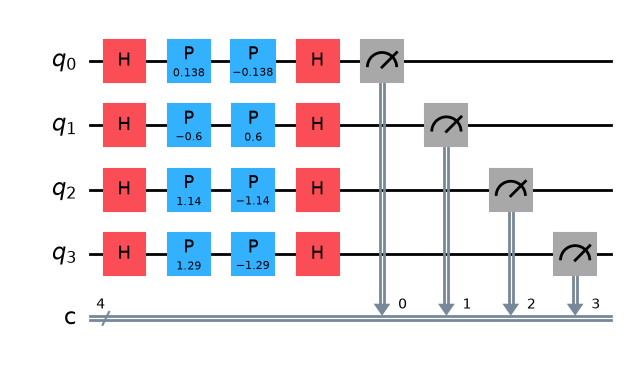

In [4]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import z_feature_map

fmap = z_feature_map(X_train.shape[1], reps=1)

def circuito_par(x_i, x_j):
    qc = QuantumCircuit(fmap.num_qubits, fmap.num_qubits)
    qc.compose(fmap.assign_parameters(dict(zip(fmap.parameters, x_j))), inplace=True)
    qc.compose(fmap.assign_parameters(dict(zip(fmap.parameters, x_i))).inverse(), inplace=True)
    qc.measure(range(fmap.num_qubits), range(fmap.num_qubits))
    return qc

# (bloque, i, j) en el mismo orden en que viajan los circuitos
indice, circuitos = [], []
for i, x_i in enumerate(X_train):
    for j, x_j in enumerate(X_train):
        if j >= i:
            indice.append(('train', i, j))
            circuitos.append(circuito_par(x_i, x_j))
for i, x_i in enumerate(X_test):
    for j, x_j in enumerate(X_train):
        indice.append(('test', i, j))
        circuitos.append(circuito_par(x_i, x_j))

print(f'{len(circuitos)} circuitos | profundidad de uno: {circuitos[0].depth()}',
      f'| puertas: {dict(circuitos[0].count_ops())}')
circuitos[0].draw('mpl', fold=-1)


## 4. Referencia local: exacta y con shots (Aer)

Dos referencias antes de gastar nada. La exacta sale del vector de estado, sin ruido de muestreo. La de Aer ejecuta la misma lista de circuitos con los mismos shots que mandaremos a IBM, así que separa el efecto del muestreo del efecto del hardware.


In [ ]:
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from sklearn.svm import SVC

def kernel_exacto(A, B):
    estados_B = [Statevector.from_instruction(
        fmap.assign_parameters(dict(zip(fmap.parameters, x)))).data for x in B]
    return np.array([[abs(np.vdot(
        Statevector.from_instruction(
            fmap.assign_parameters(dict(zip(fmap.parameters, a)))).data, b)) ** 2
        for b in estados_B] for a in A])

def conteos_a_kernels(conteos, indice, shots):
    K_train = np.zeros((len(X_train), len(X_train)))
    K_test = np.zeros((len(X_test), len(X_train)))
    todo_cero = '0' * fmap.num_qubits
    for counts, (bloque, i, j) in zip(conteos, indice):
        valor = counts.get(todo_cero, 0) / shots
        if bloque == 'train':
            K_train[i, j] = K_train[j, i] = valor
        else:
            K_test[i, j] = valor
    return K_train, K_test

def target_alignment(K, y):
    yy = np.where(y == 1, 1.0, -1.0)
    T = np.outer(yy, yy)
    return float(np.sum(K * T) / np.sqrt(np.sum(K ** 2) * np.sum(T ** 2)))

resultados = {}
def evaluar(nombre, K_train, K_test):
    clf = SVC(kernel='precomputed')
    clf.fit(K_train, y_train)
    resultados[nombre] = (K_train, K_test, clf.score(K_test, y_test))
    print(f"{nombre:10s} TA={target_alignment(K_train, y_train):.3f} "
          f"train={clf.score(K_train, y_train):.3f} test={clf.score(K_test, y_test):.3f} "
          f"diag. media={np.diag(K_train).mean():.3f}")
    return clf

K_train_exacto, K_test_exacto = kernel_exacto(X_train, X_train), kernel_exacto(X_test, X_train)
evaluar('exacto', K_train_exacto, K_test_exacto)

conteos_aer = AerSimulator().run(circuitos, shots=SHOTS).result().get_counts()
K_train_aer, K_test_aer = conteos_a_kernels(conteos_aer, indice, SHOTS)
evaluar('Aer', K_train_aer, K_test_aer)
print(f"Error medio |K_Aer - K_exacto| = {np.abs(K_train_aer - K_train_exacto).mean():.4f} "
      f"(solo ruido de muestreo, ~{1 / np.sqrt(SHOTS):.3f} por entrada)")

exacto     TA=0.649 train=1.000 test=1.000 diag. media=1.000
Aer        TA=0.649 train=1.000 test=1.000 diag. media=1.000
Error medio |K_Aer - K_exacto| = 0.0052 (solo ruido de muestreo, ~0.031 por entrada)


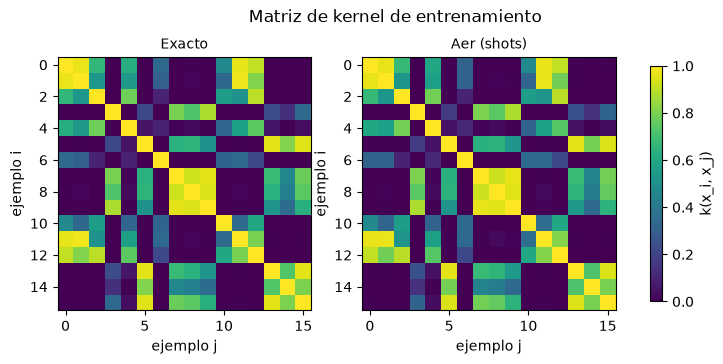

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (titulo, K) in zip(axes, [('Exacto', K_train_exacto), ('Aer (shots)', K_train_aer)]):
    im = ax.imshow(K, vmin=0, vmax=1, cmap='viridis')
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel('ejemplo j'); ax.set_ylabel('ejemplo i')
fig.colorbar(im, ax=axes, shrink=0.85, label='k(x_i, x_j)')
fig.suptitle('Matriz de kernel de entrenamiento')
plt.show()

## 5. Envío a IBM: un solo job con todos los circuitos

Elegimos IBM por una razón práctica: `SamplerV2` acepta la lista entera de circuitos en un único job. Con el patrón de IonQ de las sesiones anteriores (`backend.run(circuito)` por circuito) serían 264 envíos sueltos.

Sin token, o sin poner el interruptor a `True`, el cuaderno se salta el envío y sigue con la referencia de Aer. Cuando envíes, anota el `job_id`: desde la web de IBM Quantum puedes ver su estado sin volver a ejecutar nada.


In [7]:
import os
from getpass import getpass

backend_ibm, job_ibm = None, None
token_ibm = os.environ.get('QISKIT_IBM_TOKEN', '')
if not token_ibm:
    try:
        token_ibm = getpass('IBM Cloud API key (vacío para omitir el envío): ')
    except Exception:
        token_ibm = ''

if token_ibm:
    try:
        from qiskit_ibm_runtime import QiskitRuntimeService
        service = QiskitRuntimeService(channel='ibm_quantum_platform', token=token_ibm)
        backend_ibm = service.least_busy(simulator=False, operational=True,
                                         min_num_qubits=fmap.num_qubits)
        estado = backend_ibm.status()
        print(f'Backend elegido: {backend_ibm.name} ({backend_ibm.num_qubits} qubits) '
              f'| jobs en espera: {estado.pending_jobs}')
    except Exception as e:
        print(f'No se pudo conectar a IBM Quantum: {e}')
else:
    print('Sin API key: se omite IBM y queda la referencia local (Aer).')


qiskit_runtime_service._discover_account:WARNING:2026-11-21 18:54:23,474: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-21 18:54:26,894: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Prueba. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-21 18:54:27,362: Loading instance: Prueba, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-21 18:54:29,569: Using instance: Prueba, plan: open


Backend elegido: ibm_marrakesh (156 qubits) | jobs en espera: 0


In [9]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2

# Ponlo a True solo cuando quieras gastar el envío (un job, 264 circuitos).
EJECUTAR_EN_HARDWARE = True

circuitos_isa = None
if backend_ibm is not None:
    pm = generate_preset_pass_manager(backend=backend_ibm, optimization_level=1,
                                      seed_transpiler=7)
    circuitos_isa = pm.run(circuitos)
    uno = circuitos_isa[len(circuitos_isa) // 2]
    print(f'Transpilados para {backend_ibm.name}: profundidad de un circuito = {uno.depth()}',
          f'| puertas = {dict(uno.count_ops())}')

    if EJECUTAR_EN_HARDWARE:
        job_ibm = SamplerV2(mode=backend_ibm).run(circuitos_isa, shots=SHOTS)
        print(f'Job enviado: {job_ibm.job_id()}')
        print('Espera a que termine y ejecuta la siguiente celda (no reenvíes).')
    else:
        print('EJECUTAR_EN_HARDWARE = False: circuitos listos, envío no realizado.')
else:
    print('Sin backend IBM: nada que transpilar ni enviar.')


qiskit_runtime_service.backends:WARNING:2026-11-21 18:54:49,290: Using instance: Prueba, plan: open


Transpilados para ibm_marrakesh: profundidad de un circuito = 6 | puertas = {'rz': 6, 'sx': 4, 'measure': 4}
Job enviado: dc0tlqls2omc7389sang
Espera a que termine y ejecuta la siguiente celda (no reenvíes).


In [14]:
job_ibm.status()

'DONE'

## 6. Resultados de hardware: ¿qué le hace el ruido al kernel?

Tres cosas a mirar, en este orden. Primero la diagonal: si baja de 1, ese es el suelo de ruido del dispositivo para este circuito (preparación, puertas y lectura). Después el error medio contra el kernel exacto, que mezcla ese suelo con el ruido de muestreo que ya vimos en Aer. Y al final lo único que importa para clasificar: si el `SVC`, que solo ve márgenes, aguanta con la matriz ruidosa.


In [15]:
if job_ibm is not None:
    resultado_ibm = job_ibm.result()
    conteos_ibm = [resultado_ibm[i].data.c.get_counts() for i in range(len(circuitos))]
    K_train_ibm, K_test_ibm = conteos_a_kernels(conteos_ibm, indice, SHOTS)
    evaluar('IBM', K_train_ibm, K_test_ibm)
    print(f'Error medio |K_IBM - K_exacto| = {np.abs(K_train_ibm - K_train_exacto).mean():.4f}')
    print(f'Error medio |K_IBM - K_Aer|    = {np.abs(K_train_ibm - K_train_aer).mean():.4f} '
          '(esto aísla el hardware del muestreo)')
else:
    K_train_ibm = None
    print('Sin job de IBM: compara exacto frente a Aer en la celda siguiente.')

IBM        TA=0.648 train=1.000 test=1.000 diag. media=0.961
Error medio |K_IBM - K_exacto| = 0.0136
Error medio |K_IBM - K_Aer|    = 0.0150 (esto aísla el hardware del muestreo)


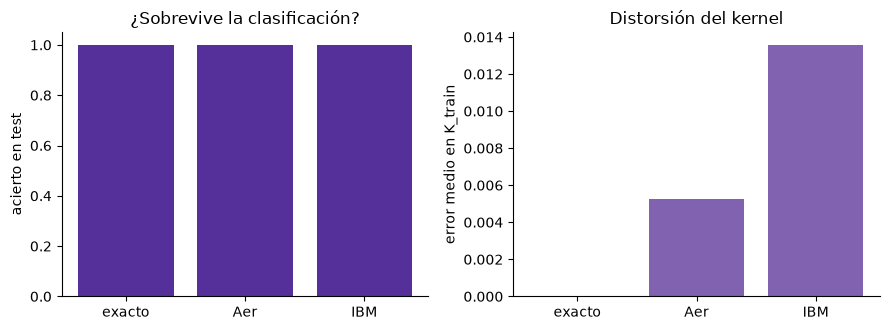

In [ ]:
nombres = list(resultados)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].bar(nombres, [resultados[n][2] for n in nombres], color='#56309a')
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel('acierto en test')
axes[0].set_title('¿Sobrevive la clasificación?')
errores = [0.0] + [float(np.abs(resultados[n][0] - K_train_exacto).mean()) for n in nombres[1:]]
axes[1].bar(nombres, errores, color='#8062b0')
axes[1].set_ylabel('error medio en K_train')
axes[1].set_title('Distorsión del kernel')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 7. La factura, en números

Lo que has pagado en este cuaderno frente a lo que costaría el QSVM de las diapositivas con el mismo backend. La gracia del ejercicio no es el acierto, que ya era bueno en el simulador, sino ver dónde se va el presupuesto: en pares de ejemplos y en shots, no en qubits.


In [17]:
enviados = len(circuitos) if job_ibm is not None else 0
print(f'Circuitos en este cuaderno: {len(circuitos)} ({len(circuitos) * SHOTS:,} shots si se envían)')
print(f'Enviados a IBM en esta sesión: {enviados}')
print(f'El QSVM completo (67 train / 33 test) serían {circuitos_unicos(67, 33)} circuitos '
      f'y {circuitos_unicos(67, 33) * SHOTS:,} shots, unas '
      f'{circuitos_unicos(67, 33) / max(len(circuitos), 1):.0f}x lo de hoy.')
if job_ibm is not None:
    print(f'Job: {job_ibm.job_id()} en {backend_ibm.name}')


Circuitos en este cuaderno: 264 (270,336 shots si se envían)
Enviados a IBM en esta sesión: 264
El QSVM completo (67 train / 33 test) serían 4489 circuitos y 4,596,736 shots, unas 17x lo de hoy.
Job: dc0tlqls2omc7389sang en ibm_marrakesh


## Para clase

- Sube `N_TRAIN` a 24 y vuelve a imprimir la cuenta de circuitos antes de tocar el interruptor. ¿Cuánto crece la factura? ¿Mejora el test lo suficiente para justificarla?
- Repite con `zz_feature_map(..., reps=1)`: el circuito ya entrelaza. Compara diagonal media y error medio frente a hoy. ¿Dónde se nota primero el ruido, en la diagonal o en el acierto?
- Versión IonQ: toma solo los pares de la diagonal y unos pocos fuera de ella (una docena de circuitos) y envíalos con el patrón `qiskit-ionq` de la sesión 01. Compara su diagonal con la de IBM y con la de Aer.
- Si repites el envío a otra hora o en otro backend, guarda el `job_id` y compara la diagonal media entre ejecuciones. ¿Es estable el suelo de ruido?
